## Step 1: Import Libraries
Load the pandas, numpy, plotting, and TensorFlow tools we'll need, plus scikit-learn helpers for splitting data and preprocessing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

## Step 2: Load the Dataset
Read the medical insurance CSV into a DataFrame and preview the first few rows.

In [2]:
medical_df = pd.read_csv('/kaggle/input/datasets/mirichoi0218/insurance/insurance.csv')

In [3]:
medical_df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Step 3: Explore the Data
Check data types, missing values, duplicates, and summary statistics to understand what we're working with.

In [4]:
def basic_df_checks(df):
    print("=== BASIC DATAFRAME CHECKS ===")
    print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns\n")

    print("Column Data Types:")
    print(df.dtypes)
    print("\nMissing Values:")
    print(df.isnull().sum())
    print("\nDuplicate Rows:", df.duplicated().sum())

    print("\n=== NUMERIC SUMMARY ===")
    display(df.describe(include=[np.number]))

    print("\n=== CATEGORICAL SUMMARY ===")
    display(df.describe(include=['object', 'category']))

    print("\nUnique Values per Column:")
    for col in df.columns:
        print(f"{col}: {df[col].nunique()}")


In [5]:
basic_df_checks(medical_df)

=== BASIC DATAFRAME CHECKS ===
Shape: 1338 rows × 7 columns

Column Data Types:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate Rows: 1

=== NUMERIC SUMMARY ===


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010



=== CATEGORICAL SUMMARY ===


,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364



Unique Values per Column:
age: 47
sex: 2
bmi: 548
children: 6
smoker: 2
region: 4
charges: 1337


## Step 4: Clean the Data
Remove duplicate rows so they don't skew the model.

In [6]:
medical_df.drop_duplicates(inplace=True)

In [7]:
medical_df.duplicated().sum()

np.int64(0)

## Step 5: Inspect Categorical Columns
Look at the unique values in each categorical column (sex, smoker, region) before encoding them.

In [8]:
cat_cols = medical_df.select_dtypes(include = ['object']).columns.to_list()
cat_cols

['sex', 'smoker', 'region']

In [9]:
for col in cat_cols:
    print(f"{col}: {medical_df[col].nunique()}")
    print(medical_df[col].unique())

sex: 2
['female' 'male']
smoker: 2
['yes' 'no']
region: 4
['southwest' 'southeast' 'northwest' 'northeast']


## Step 6: Visualize the Target Variable
Plot the distribution of `charges` (the value we're trying to predict) to check its shape.

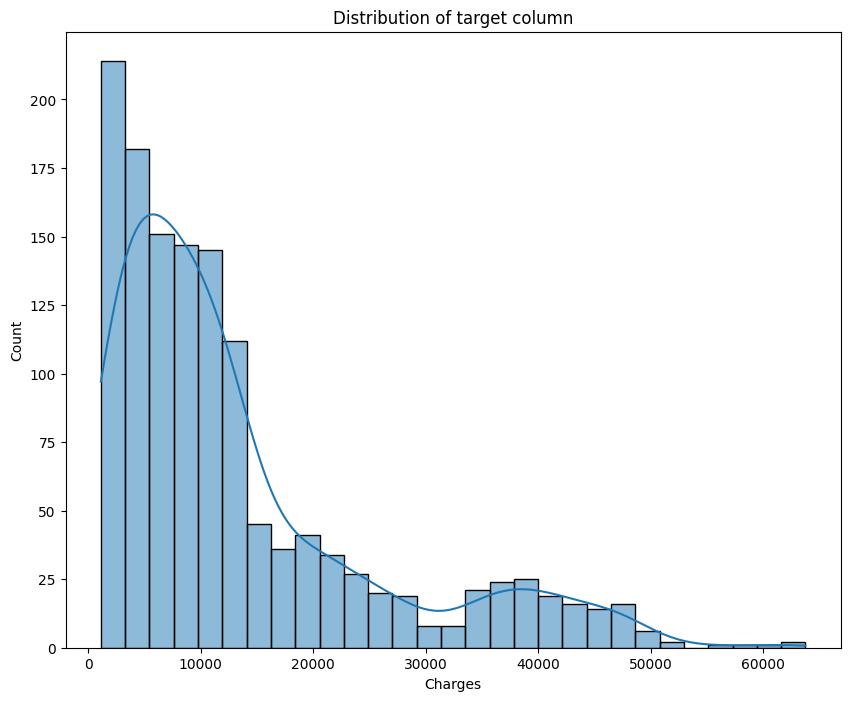

In [10]:
plt.figure(figsize=(10, 8))
sns.histplot(data=medical_df, x='charges', kde=True)
plt.xlabel('Charges')
plt.title('Distribution of target column')
plt.show()

## Step 7: Split Features and Target
Separate the input columns (X) from the target column (y).

In [11]:
X = medical_df.drop(columns = ['charges'])
y = medical_df['charges']

## Step 8: Split into Train / Validation / Test Sets
First split off a temporary set, then split that temporary set again to get separate validation and test sets.

In [12]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size = 0.3, random_state = 42)

In [13]:
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size = 0.5, random_state = 42)

## Step 9: Preprocess the Data
Scale numeric columns and one-hot encode categorical columns, then apply this preprocessing to train, validation, and test sets.

In [14]:
num_cols = ['age', 'bmi', 'children']

numerical_pipeline = Pipeline([('scaler', StandardScaler())])

In [15]:
cat_cols = ['sex', 'smoker', 'region']

categorical_pipeline = Pipeline([('encoder', OneHotEncoder(handle_unknown='ignore'))])

In [16]:
preprocessor = ColumnTransformer(transformers = [
    ('num', numerical_pipeline, num_cols),
    ('cat', categorical_pipeline, cat_cols)
])

In [17]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
X_val_processed = preprocessor.transform(X_val)

## Step 10: Build the Neural Network
Define a simple feedforward network: an input layer sized to match our processed features, a few hidden Dense layers with ReLU activation, and a single output neuron for the predicted charge.

In [18]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape = (X_train_processed.shape[1],)),
    tf.keras.layers.Dense(64, activation = 'relu'),
    tf.keras.layers.Dense(32, activation = 'relu'),
    tf.keras.layers.Dense(32, activation = 'relu'),
    tf.keras.layers.Dense(1)
])

I0000 00:00:1788375788.116939      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1788375788.119950      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [19]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,937 (15.38 KB)

 Trainable params: 3,937 (15.38 KB)

 Non-trainable params: 0 (0.00 B)

## Step 11: Compile the Model
Set the optimizer, loss function (MSE, standard for regression), and a tracked metric (MAE).

In [20]:
model.compile(optimizer = 'adam', loss = 'mse', metrics = ['mae'])

## Step 12: Set Up Early Stopping
Stop training automatically once validation loss stops improving, and restore the best weights.

In [21]:
callbacks = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, restore_best_weights = True)

## Step 13: Train the Model
Fit the model on the training data, using the validation set to monitor performance each epoch.

In [22]:
history = model.fit(X_train_processed, y_train,
                   validation_data = (X_val_processed, y_val),
                   epochs = 200, batch_size = 32, callbacks = [callbacks])

Epoch 1/200
23/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 359599909.5652 - mae: 14222.3640 

I0000 00:00:1788375792.092130     134 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - loss: 305693280.0000 - mae: 13034.6406 - val_loss: 376778528.0000 - val_mae: 14342.0723
Epoch 2/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 305623008.0000 - mae: 13032.0420 - val_loss: 376628512.0000 - val_mae: 14337.0537
Epoch 3/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 305322144.0000 - mae: 13021.0762 - val_loss: 375947008.0000 - val_mae: 14314.4424
Epoch 4/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 304088576.0000 - mae: 12976.4258 - val_loss: 373447648.0000 - val_mae: 14231.8125
Epoch 5/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 300208928.0000 - mae: 12834.9980 - val_loss: 366458656.0000 - val_mae: 13999.0264
Epoch 6/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 290847424.0000 - mae: 12485.8506 - val_loss: 350902496.0000 - val_mae: 13471.6191
Epoch 7/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 272346240.0000 - mae: 11772.2812 - val_loss: 323293568.0000 - val_mae: 12482.3008
Epoch 8/200
30/30 ━━━━━━

## Step 14: Plot Training vs Validation Loss
Visualize how loss changed over training to check for overfitting or underfitting.

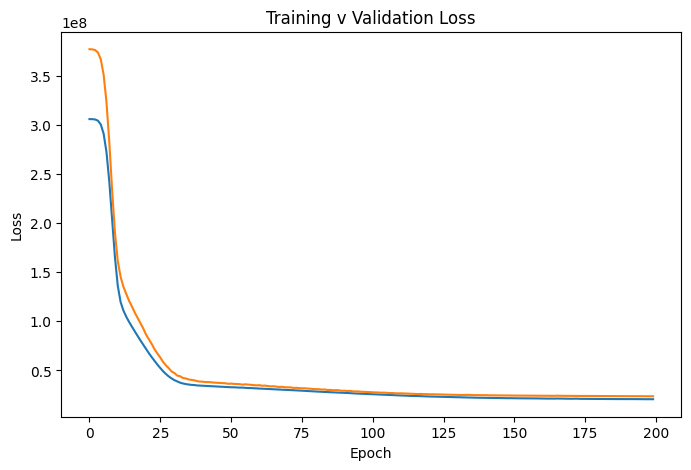

In [23]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label = 'Training Loss')
plt.plot(history.history['val_loss'], label = 'Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training v Validation Loss')
plt.legend
plt.show()

## Step 15: Make Predictions on the Test Set
Use the trained model to predict charges for the held-out test set.

In [24]:
y_pred = model.predict(X_test_processed).ravel()

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


## Step 16: Evaluate Model Performance
Compare predictions to actual values using MAE, MSE, RMSE, and R² to see how well the model performed.

In [25]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Absolute Error:', {mae})
print(f'Mean Squared Error:', {mse})
print(f'Root Mean Squared Error:', {rmse})
print(f'R2 Score:', {r2})

Mean Absolute Error: {2783.0200051593397}
Mean Squared Error: {24364573.7523081}
Root Mean Squared Error: {4936.04839444551}
R2 Score: {0.8572309718232213}
